In [3]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

In [4]:
GROUP = "C2"
DTYPE="G_H"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C2_10,27,"[DATA/TRAINING/C2/C2_10/IMG_6566.HEIC, DATA/TR..."
1,C2_11,25,"[DATA/TRAINING/C2/C2_11/IMG_6666.HEIC, DATA/TR..."
2,C2_12,25,"[DATA/TRAINING/C2/C2_12/IMG_6789.HEIC, DATA/TR..."
3,C2_13,29,"[DATA/TRAINING/C2/C2_13/IMG_6944.HEIC, DATA/TR..."
4,C2_14,25,"[DATA/TRAINING/C2/C2_14/IMG_7189.HEIC, DATA/TR..."
5,C2_15,28,"[DATA/TRAINING/C2/C2_15/IMG_7315.HEIC, DATA/TR..."
6,C2_16,28,"[DATA/TRAINING/C2/C2_16/IMG_7447.HEIC, DATA/TR..."


In [5]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [6]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [7]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

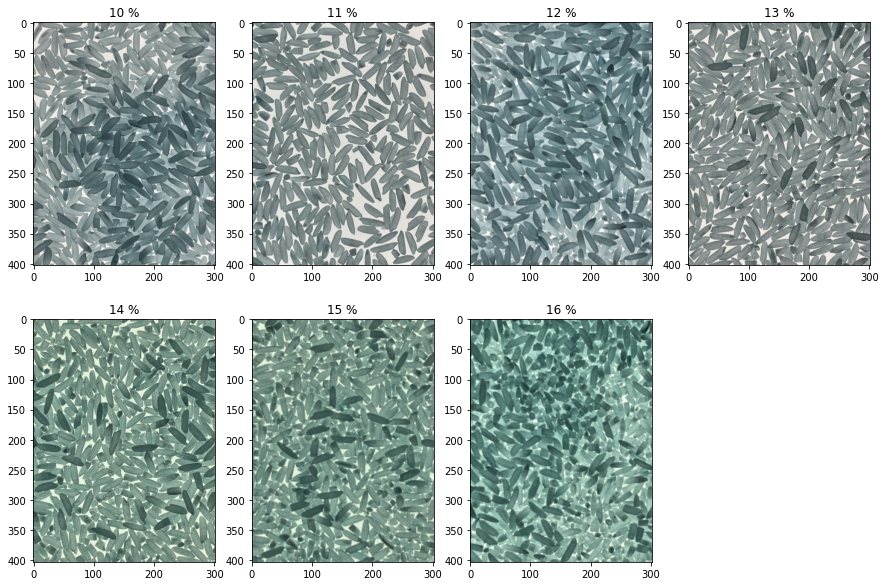

In [8]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [9]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [97]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [98]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000050,0.000725,0.004522,...,0.080769,0.042826,0.019675,25,44,1008,756,3,IMG_6566.HEIC,10
1,0.0,0.0,0.000000,0.000006,0.000006,0.000000,0.000011,0.000169,0.000817,0.001556,...,0.124081,0.060214,0.018970,25,44,1008,756,3,IMG_6567.HEIC,10
2,0.0,0.0,0.000027,0.000060,0.000087,0.000147,0.000223,0.000610,0.000752,0.001182,...,0.105134,0.043685,0.012290,25,44,1008,756,3,IMG_6568.HEIC,10
3,0.0,0.0,0.000000,0.000000,0.000011,0.000000,0.000011,0.000211,0.000701,0.001938,...,0.121068,0.055596,0.017740,25,44,1008,756,3,IMG_6569.HEIC,10
4,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000005,0.000204,0.000366,0.001077,...,0.066022,0.021572,0.002990,25,44,1008,756,3,IMG_6570.HEIC,10
5,0.0,0.0,0.000000,0.000012,0.000040,0.000029,0.000213,0.000564,0.000771,0.001317,...,0.099543,0.048472,0.016631,25,44,1008,756,3,IMG_6571.HEIC,10
6,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000138,0.000220,0.000609,...,0.055147,0.016229,0.001495,25,44,1008,756,3,IMG_6572.HEIC,10
7,0.0,0.0,0.000000,0.000000,0.000024,0.000083,0.000208,0.000244,0.000469,0.001111,...,0.128513,0.063077,0.030617,25,44,1008,756,3,IMG_6573.HEIC,10
8,0.0,0.0,0.000006,0.000023,0.000023,0.000046,0.000139,0.000243,0.000255,0.001117,...,0.118350,0.067653,0.028307,25,44,1008,756,3,IMG_6574.HEIC,10
9,0.0,0.0,0.000000,0.000024,0.000041,0.000059,0.000213,0.000178,0.000569,0.001078,...,0.120191,0.059781,0.027373,25,44,1008,756,3,IMG_6575.HEIC,10


# Classification

In [99]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [100]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [101]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [102]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

### Random Forest Classifier

In [103]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [105]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.736842,0.761905,0.761905,0.761905,G_H,C2,RF_C,25,44,1008,756,3
1,2,0.736842,0.800000,0.714286,0.754717,G_H,C2,RF_C,25,44,1008,756,3
2,3,0.842105,0.880952,0.857143,0.868885,G_H,C2,RF_C,25,44,1008,756,3
3,4,0.842105,0.857143,0.809524,0.832653,G_H,C2,RF_C,25,44,1008,756,3
4,5,0.736842,0.654762,0.714286,0.683230,G_H,C2,RF_C,25,44,1008,756,3
5,6,0.684211,0.728571,0.666667,0.696246,G_H,C2,RF_C,25,44,1008,756,3
6,7,0.736842,0.809524,0.761905,0.784993,G_H,C2,RF_C,25,44,1008,756,3
7,8,0.777778,0.785714,0.761905,0.773626,G_H,C2,RF_C,25,44,1008,756,3
8,9,0.555556,0.607143,0.523810,0.562406,G_H,C2,RF_C,25,44,1008,756,3
9,10,0.666667,0.607143,0.690476,0.646134,G_H,C2,RF_C,25,44,1008,756,3


In [106]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C2,RF_C,0.731579,0.72619,0.736479,0.749286


### MLP Classifier

In [107]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [108]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [109]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.684211,0.750000,0.690476,0.719008,G_H,C2,MLP_C,25,44,1008,756,3
1,2,0.684211,0.714286,0.642857,0.676692,G_H,C2,MLP_C,25,44,1008,756,3
2,3,0.736842,0.692857,0.690476,0.691665,G_H,C2,MLP_C,25,44,1008,756,3
3,4,0.578947,0.692857,0.547619,0.611736,G_H,C2,MLP_C,25,44,1008,756,3
4,5,0.421053,0.535714,0.428571,0.476190,G_H,C2,MLP_C,25,44,1008,756,3
5,6,0.894737,0.928571,0.857143,0.891429,G_H,C2,MLP_C,25,44,1008,756,3
6,7,0.421053,0.523810,0.452381,0.485482,G_H,C2,MLP_C,25,44,1008,756,3
7,8,0.555556,0.523810,0.547619,0.535450,G_H,C2,MLP_C,25,44,1008,756,3
8,9,0.611111,0.702381,0.595238,0.644386,G_H,C2,MLP_C,25,44,1008,756,3
9,10,0.666667,0.702381,0.642857,0.671302,G_H,C2,MLP_C,25,44,1008,756,3


In [110]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C2,MLP_C,0.625439,0.609524,0.640334,0.676667


### XGBoost Classifier

In [111]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [112]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.578947,0.607143,0.571429,0.588745,G_H,C2,XGB_C,25,44,1008,756,3
1,2,0.789474,0.871429,0.785714,0.826355,G_H,C2,XGB_C,25,44,1008,756,3
2,3,0.842105,0.892857,0.833333,0.862069,G_H,C2,XGB_C,25,44,1008,756,3
3,4,0.842105,0.857143,0.833333,0.845070,G_H,C2,XGB_C,25,44,1008,756,3
4,5,0.421053,0.461905,0.404762,0.431450,G_H,C2,XGB_C,25,44,1008,756,3
5,6,0.842105,0.845238,0.857143,0.851149,G_H,C2,XGB_C,25,44,1008,756,3
6,7,0.789474,0.857143,0.809524,0.832653,G_H,C2,XGB_C,25,44,1008,756,3
7,8,0.666667,0.619048,0.690476,0.652814,G_H,C2,XGB_C,25,44,1008,756,3
8,9,0.388889,0.380952,0.357143,0.368664,G_H,C2,XGB_C,25,44,1008,756,3
9,10,0.666667,0.714286,0.666667,0.689655,G_H,C2,XGB_C,25,44,1008,756,3


In [113]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C2,XGB_C,0.682749,0.680952,0.694862,0.710714


# External validation


In [114]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C2_10,5,"[DATA/TEST/C2/C2_10/IMG_6560.HEIC, DATA/TEST/C..."
1,C2_11,5,"[DATA/TEST/C2/C2_11/IMG_6656.HEIC, DATA/TEST/C..."
2,C2_12,5,"[DATA/TEST/C2/C2_12/IMG._6813.HEIC, DATA/TEST/..."
3,C2_13,5,"[DATA/TEST/C2/C2_13/IMG_6918.HEIC, DATA/TEST/C..."
4,C2_14,5,"[DATA/TEST/C2/C2_14/IMG_7179.HEIC, DATA/TEST/C..."
5,C2_15,5,"[DATA/TEST/C2/C2_15/IMG_7305.HEIC, DATA/TEST/C..."
6,C2_16,5,"[DATA/TEST/C2/C2_16/IMG_7437.HEIC, DATA/TEST/C..."


In [115]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [116]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [117]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000006,0.000018,0.000318,0.001186,...,0.073254,0.066786,0.041410,25,44,1008,756,3,IMG_6560.HEIC,10
1,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000024,0.000179,0.000740,...,0.063204,0.042687,0.020237,25,44,1008,756,3,IMG_6561.HEIC,10
2,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000049,0.000306,0.002037,...,0.087118,0.043137,0.019791,25,44,1008,756,3,IMG_6563.HEIC,10
3,0.0,0.0,0.000000,0.000000,0.000000,0.000012,0.000144,0.000216,0.000630,0.001999,...,0.028432,0.046414,0.049745,25,44,1008,756,3,IMG_6564.HEIC,10
4,0.0,0.0,0.000000,0.000000,0.000450,0.000259,0.000142,0.000598,0.001215,0.003607,...,0.102945,0.048451,0.020070,25,44,1008,756,3,IMG_6565.HEIC,10
0,0.0,0.0,0.000005,0.000010,0.000000,0.000031,0.000126,0.000241,0.000661,0.002024,...,0.106501,0.052946,0.013825,25,44,1008,756,3,IMG_6656.HEIC,11
1,0.0,0.0,0.000000,0.000015,0.000005,0.000005,0.000062,0.000139,0.000375,0.000903,...,0.112979,0.062710,0.021531,25,44,1008,756,3,IMG_6658.HEIC,11
2,0.0,0.0,0.000000,0.000000,0.000000,0.000012,0.000150,0.000376,0.001076,0.001191,...,0.096562,0.067795,0.029178,25,44,1008,756,3,IMG_6660.HEIC,11
3,0.0,0.0,0.000000,0.000016,0.000084,0.000079,0.000157,0.000724,0.001003,0.001087,...,0.064083,0.019830,0.002079,25,44,1008,756,3,IMG_6661.HEIC,11
4,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000054,0.000263,0.000883,0.002739,...,0.097257,0.057938,0.023589,25,44,1008,756,3,IMG_6664.HEIC,11


In [118]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [119]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [120]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [121]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [122]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.33      0.20      0.25         5
     Class 1       0.33      0.20      0.25         5
     Class 2       0.45      1.00      0.62         5
     Class 3       0.60      0.60      0.60         5
     Class 4       0.20      0.20      0.20         5
     Class 5       0.25      0.20      0.22         5
     Class 6       0.50      0.40      0.44         5

    accuracy                           0.40        35
   macro avg       0.38      0.40      0.37        35
weighted avg       0.38      0.40      0.37        35



## MLP

In [123]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [124]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.33      0.20      0.25         5
     Class 1       0.33      0.20      0.25         5
     Class 2       0.36      0.80      0.50         5
     Class 3       0.50      0.40      0.44         5
     Class 4       0.33      0.40      0.36         5
     Class 5       0.33      0.20      0.25         5
     Class 6       0.40      0.40      0.40         5

    accuracy                           0.37        35
   macro avg       0.37      0.37      0.35        35
weighted avg       0.37      0.37      0.35        35



## XGBC

In [125]:
y_pred = modelXGBC.predict(X_test_scale) 

In [126]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.50      0.60      0.55         5
     Class 2       0.50      1.00      0.67         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.50      0.40      0.44         5
     Class 5       0.33      0.20      0.25         5
     Class 6       0.20      0.20      0.20         5

    accuracy                           0.43        35
   macro avg       0.36      0.43      0.38        35
weighted avg       0.36      0.43      0.38        35

